# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
W, H, C, B = 1920, 1080, 3, 1                      # 8 bits = 1 byte per channel
frame_bytes = W * H * C * B
frame_mb = frame_bytes / 1024**2

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60                 # f x T

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
N_CAM = 400
fleet_bytes = frame_bytes * frames_per_day * N_CAM
fleet_tb = fleet_bytes / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_frame_bytes = 640 * 360 * C * B
fleet_tb_small = small_frame_bytes * (10 * 24 * 60 * 60) * N_CAM / 1024**4
pct_pixels_remaining = (640 * 360) / (W * H) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")
print(f"Overall reduction: {fleet_tb / fleet_tb_small:.0f}x  (9x fewer pixels x 3x fewer frames)")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%
Overall reduction: 27x  (9x fewer pixels x 3x fewer frames)


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_
The saving is real: 5,866 TB/day drops to about 217 TB/day, roughly 27× less. But going to 640 × 360 keeps only
11.11% of the pixels in each frame, and that detail is gone for good.

- **Spatial:** a **number plate or a face**. A plate that covers maybe 40 × 12 px at 1080p becomes about 13 × 4 px
  at 360p. Upscaling it later only *interpolates* between the samples we kept (Slide 13). It can make the plate
  look smoother, but it cannot bring back characters that were never sampled.
- **Temporal:** **fast, short actions**. At 10 fps there is a 100 ms gap between frames. Something quick, like
  a hand throwing an object at the window or the exact moment the person starts running, can happen almost
  entirely between two frames. An object can also jump so far from one frame to the next that we can no longer
  be sure it is the same object (the correspondence problem, Slides 36–37). We would see a "before" and an
  "after" but not the action that links them.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

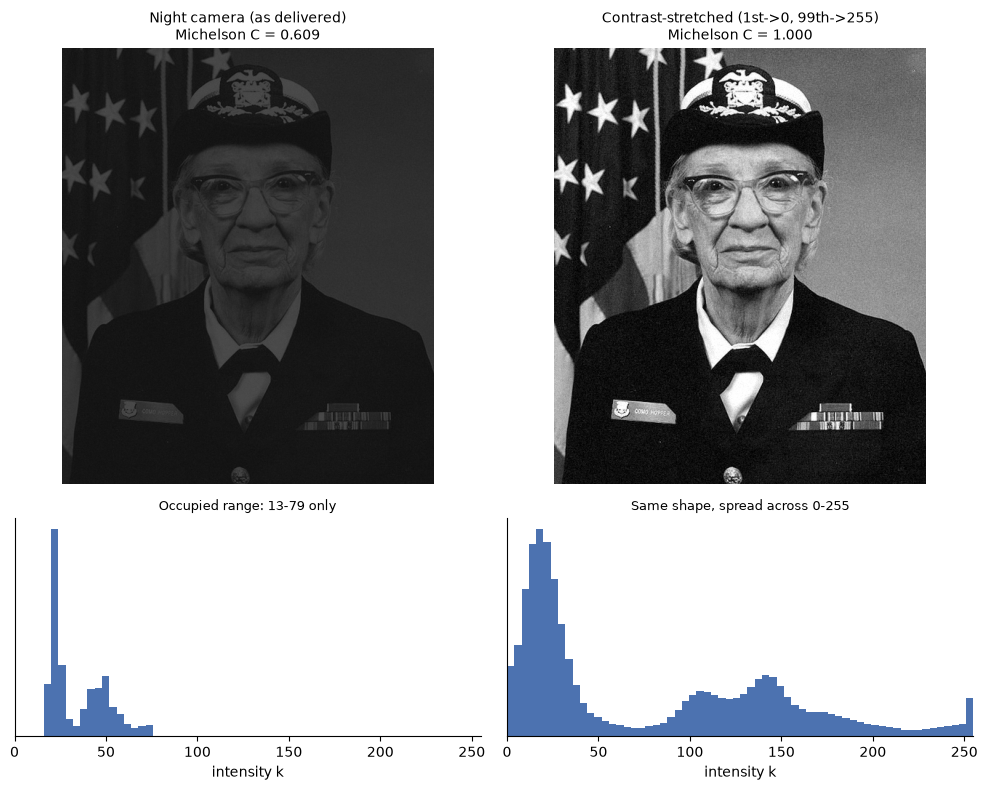

Contrast before: 0.609  ->  after: 1.000
1st/99th percentiles of night image: 17.8 / 73.4  (only 56 of 256 grey levels used)


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

q1, q99 = np.percentile(stretched, [1, 99])
c_after = michelson(q99, q1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for col, (im, name, c) in enumerate([(night_still, "Night camera (as delivered)", c_before),
                                     (stretched, "Contrast-stretched (1st->0, 99th->255)", c_after)]):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"{name}\nMichelson C = {c:.3f}", fontsize=10); axes[0, col].axis("off")
    axes[1, col].hist(im.ravel(), bins=64, range=(0, 255), color="#4C72B0")
    axes[1, col].set_xlim(0, 255); axes[1, col].set_yticks([]); axes[1, col].set_xlabel("intensity k")
axes[1, 0].set_title(f"Occupied range: {night_still.min():.0f}-{night_still.max():.0f} only", fontsize=9)
axes[1, 1].set_title("Same shape, spread across 0-255", fontsize=9)

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")
print(f"1st/99th percentiles of night image: {p1:.1f} / {p99:.1f}  (only {p99-p1:.0f} of 256 grey levels used)")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

The night histogram is **left-concentrated and narrow**. Almost every pixel sits between about 18 and 73
(1st–99th percentile), so only about 56 of the 256 grey levels are used. That shape means the image is **dark and
low-contrast**. It is not clipped, though: nothing is piled up at 0 or 255. There are also **two peaks**, a big
dark one (the uniform and background) and a smaller brighter one (face, cap and shirt), so two intensity
populations are present but squeezed close together. The robust Michelson contrast is only **0.61**.

Stretching is just a linear remap, *I' = (I − 18)/(73 − 18) × 255*. Because it is monotonic, the order of the
pixels and the shape of the histogram stay the same; the histogram is only spread out across 0–255. No new
information is created. What changes is that the differences between neighbouring pixels become large enough for
our eyes to see. Early vision responds to **differences**, so edges like the glasses, the badge and the stars
become visible. Contrast goes to **1.00**, which is expected by construction, because the 1st percentile is mapped
to 0. The cost is that about 1% of pixels at each end are now clipped.

A histogram only **counts** intensities and throws away *where* they are. The demo showed a bright disc, two bands
and random salt-and-pepper with identical histograms. So the histogram can tell us *how* the image is exposed
and whether the fix worked, but never *what* is in the picture. For that we need the spatial arrangement, which
means the image itself.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

STANDING (<3 px/s)  :   68.8 s ->   78.1 s  (9.3 s)
RUNNING (>25 px/s)  :   78.6 s ->   86.0 s  (7.4 s)

Audio > -20 dB first at frame 2250 (t = 75.00 s, -4.6 dB)
Brightness jump > 40 at frame 3000 (t = 100.00 s, 62 -> 148)


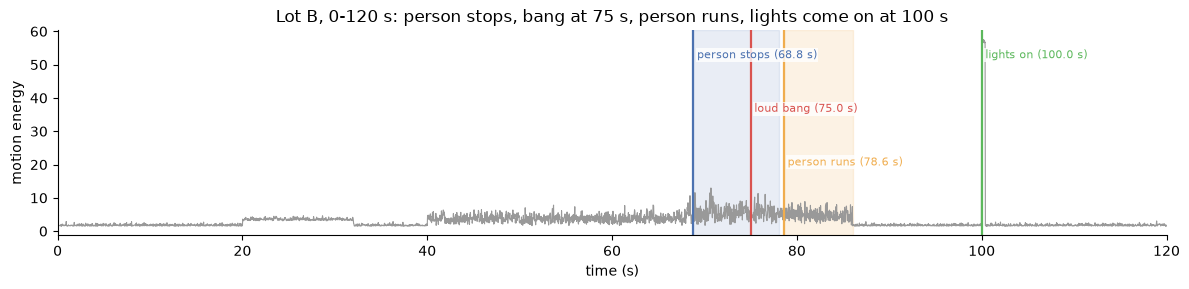

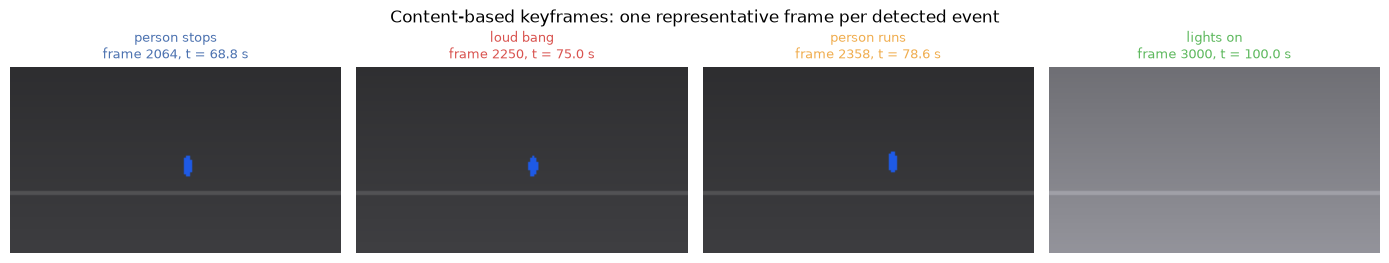

In [4]:
# TODO 1: person speed (px/s)
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))   # displacement over 1 s = px/s

def ranges(mask, min_len=FPS):
    """Contiguous runs of True lasting at least min_len frames -> list of (start_idx, end_idx)."""
    mask = mask.fillna(False).astype(bool).values
    out, start = [], None
    for i, m in enumerate(np.append(mask, False)):
        if m and start is None: start = i
        elif not m and start is not None:
            if i - start >= min_len: out.append((start, i - 1))
            start = None
    return out

# TODO 2: standing / running time ranges (print the first and last time of each)
# tracking jitter makes the raw speed flicker across 3 px/s, so classify on a 1 s rolling median
speed_s = speed.rolling(FPS, center=True, min_periods=FPS // 2).median()
standing = ranges(speed_s < 3)
running = ranges(speed_s > 25)
for label, rs in [("STANDING (<3 px/s)", standing), ("RUNNING (>25 px/s)", running)]:
    for a, b in rs:
        print(f"{label:20s}: {cctv.time_s[a]:6.1f} s -> {cctv.time_s[b]:6.1f} s  ({cctv.time_s[b]-cctv.time_s[a]:.1f} s)")

# TODO 3: event frame indices
above = cctv.audio_level_db > -20
audio_event_idx = int(cctv.index[above & ~above.shift(fill_value=False)][0])        # first upward crossing
lighting_event_idx = int(cctv.index[cctv.mean_brightness.diff() > 40][0])
print(f"\nAudio > -20 dB first at frame {audio_event_idx} (t = {cctv.time_s[audio_event_idx]:.2f} s, "
      f"{cctv.audio_level_db[audio_event_idx]:.1f} dB)")
print(f"Brightness jump > 40 at frame {lighting_event_idx} (t = {cctv.time_s[lighting_event_idx]:.2f} s, "
      f"{cctv.mean_brightness[lighting_event_idx-1]:.0f} -> {cctv.mean_brightness[lighting_event_idx]:.0f})")

events = [(standing[0][0], "person stops", "#4C72B0"),
          (audio_event_idx, "loud bang", "#D9534F"),
          (running[0][0], "person runs", "#f0ad4e"),
          (lighting_event_idx, "lights on", "#5cb85c")]

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, color="#999999", lw=0.8)
for a, b in standing: ax.axvspan(cctv.time_s[a], cctv.time_s[b], color="#4C72B0", alpha=0.12)
for a, b in running:  ax.axvspan(cctv.time_s[a], cctv.time_s[b], color="#f0ad4e", alpha=0.15)
ymax = cctv.motion_energy.max()
for k, (i, name, col) in enumerate(events):
    t = cctv.time_s[i]
    ax.axvline(t, color=col, lw=1.6)
    ax.text(t + 0.4, ymax * (0.95 - 0.28 * (k % 3)), f"{name} ({t:.1f} s)", color=col, fontsize=8, va="top",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
ax.set_xlabel("time (s)"); ax.set_ylabel("motion energy"); ax.set_xlim(0, 120)
ax.set_title("Lot B, 0-120 s: person stops, bang at 75 s, person runs, lights come on at 100 s")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(14, 2.8))
for ax, (i, name, col) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[i])); ax.axis("off")
    ax.set_title(f"{name}\nframe {i}, t = {cctv.time_s[i]:.1f} s", color=col, fontsize=9)
plt.suptitle("Content-based keyframes: one representative frame per detected event")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

Uniform sampling every 20 s would grab frames at 0, 20, 40, 60, 80 and 100 s. The **bang at 75 s** would almost
certainly be missed. It is a sub-second audio event with no visible change in the frame, and the nearest samples
(60 s and 80 s) show a walking person and a running person. The **moment the person starts running (78.6 s)**
would also be lost; at best we would see them already mid-run at 80 s with no clue why. The "person stops"
moment (68.8 s) falls between samples too. The 100 s lights-on event is only caught by luck, because it happens
to land exactly on a sample. Activity here is **sparse**: about 10 s of interesting behaviour in a 120 s clip.
Uniform sampling spends its frames on empty parking lot.

What I used instead is **content-based keyframe selection** (Slide 40). Keyframes are placed where the data
changes: a speed threshold, an audio level crossing, a brightness jump. Each keyframe then represents an
**event** rather than a clock tick.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

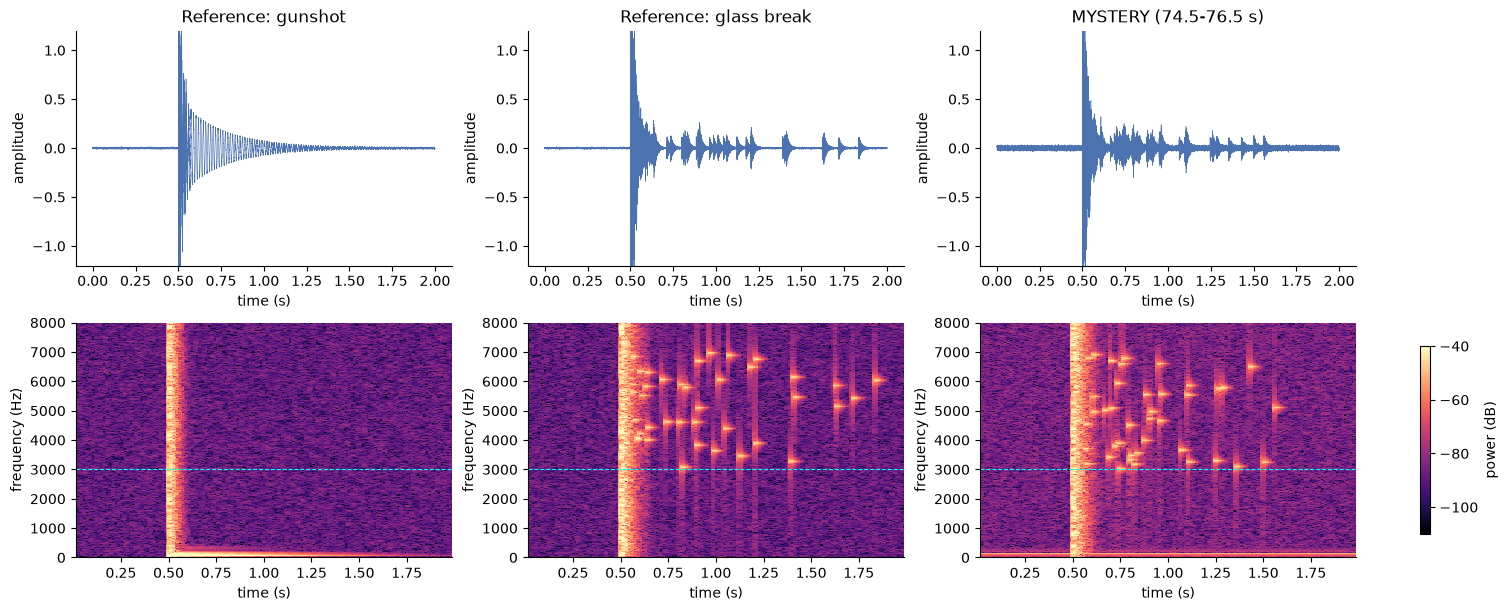

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
VERDICT: the 75 s sound is BREAKING GLASS -- 87% of its post-impact energy is above 3 kHz (glass ref 99%, gunshot ref 0%).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
fig.set_layout_engine("constrained")
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
specs = {}
for col, (name, x) in enumerate(clips.items()):
    t = np.arange(x.size) / FS
    axes[0, col].plot(t, x, lw=0.4, color="#4C72B0")
    axes[0, col].set_title(name); axes[0, col].set_ylim(-1.2, 1.2)
    axes[0, col].set_xlabel("time (s)"); axes[0, col].set_ylabel("amplitude")
    f, tt, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    specs[name] = (f, tt, Sxx)
    pcm = axes[1, col].pcolormesh(tt, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
    axes[1, col].set_ylim(0, 8000); axes[1, col].set_xlabel("time (s)"); axes[1, col].set_ylabel("frequency (Hz)")
    axes[1, col].axhline(3000, color="cyan", ls="--", lw=0.8)
fig.colorbar(pcm, ax=axes[1, :], label="power (dB)", shrink=0.8)

plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, (f, tt, Sxx) in specs.items():
    win = (tt >= 0.5 + 0.2) & (tt <= 0.5 + 1.2)
    E = Sxx[:, win]
    hf_fraction[name] = round(float(E[f > 3000].sum() / E.sum()), 3)

print(hf_fraction)
# TODO 4: verdict
gun, glass, mys = hf_fraction.values()
verdict = "BREAKING GLASS" if abs(mys - glass) < abs(mys - gun) else "GUNSHOT"
print(f"VERDICT: the 75 s sound is {verdict} -- {mys:.0%} of its post-impact energy is above 3 kHz "
      f"(glass ref {glass:.0%}, gunshot ref {gun:.0%}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

Not confidently. All three waveforms look like "a big spike at 0.5 s that decays". You can see a few small bursts
after the impact in the glass and mystery clips, but they could just as easily be echoes, footsteps or noise. A
waveform only shows **amplitude against time**. It tells us *when* something loud happened, not *what* it was.

The spectrogram adds frequency, so each clip becomes **time × frequency × magnitude** (x-axis, y-axis, colour).
All three clips start with the same **vertical stripe** at 0.5 s, the broadband impact, so the impact alone does not
separate them. What decides the case is what happens afterwards:
- the gunshot leaves a **low horizontal band** (the ~70 Hz boom) and nothing above 3 kHz, so only **0.3%** of its
  post-impact energy is above 3 kHz;
- the glass break leaves **scattered high-frequency specks** between 3 and 7 kHz (the tinkling shards), giving **98.9%**;
- the mystery clip shows the **same scattered 3–7 kHz specks**, giving **87.3%**. It is a bit lower than the
  reference only because the background 120 Hz electrical hum (the thin band at the bottom) adds some low-frequency energy.

The scattered specks decided the verdict: **breaking glass, not a gunshot**.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

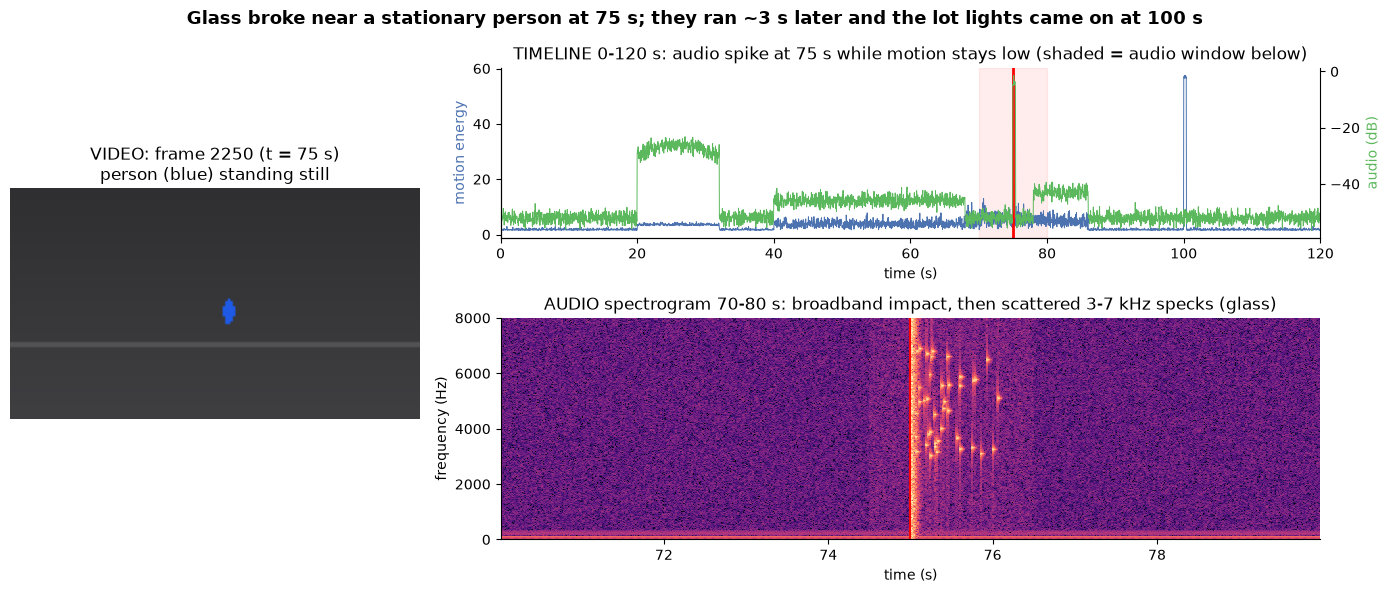

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
i_sel = int(round(t_sel * FPS))
ax_f = fig.add_subplot(gs[:, 0]); ax_t = fig.add_subplot(gs[0, 1]); ax_s = fig.add_subplot(gs[1, 1])

# 1. video frame at t_sel
ax_f.imshow(render_frame(cctv.iloc[i_sel])); ax_f.axis("off")
ax_f.set_title(f"VIDEO: frame {i_sel} (t = {t_sel:.0f} s)\nperson (blue) standing still")

# 2. full 120 s timeline: motion + audio level, red marker at t_sel
ax_t.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.7)
ax_t.set_ylabel("motion energy", color="#4C72B0"); ax_t.set_xlim(0, 120)
ax_t2 = ax_t.twinx()
ax_t2.plot(cctv.time_s, cctv.audio_level_db, color="#5cb85c", lw=0.7)
ax_t2.set_ylabel("audio (dB)", color="#5cb85c"); ax_t2.spines["right"].set_visible(True)
ax_t.axvline(t_sel, color="red", lw=2)
ax_t.axvspan(70, 80, color="red", alpha=0.07)
ax_t.set_title("TIMELINE 0-120 s: audio spike at 75 s while motion stays low (shaded = audio window below)")
ax_t.set_xlabel("time (s)")

# 3. spectrogram of x_audio 70-80 s, same marker
f, tt, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_s.pcolormesh(tt + t_audio[0], f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
ax_s.axvline(t_sel, color="red", lw=1.5)
ax_s.set_ylim(0, 8000); ax_s.set_xlabel("time (s)"); ax_s.set_ylabel("frequency (Hz)")
ax_s.set_title("AUDIO spectrogram 70-80 s: broadband impact, then scattered 3-7 kHz specks (glass)")

# 4. conclusion-style title
fig.suptitle("Glass broke near a stationary person at 75 s; they ran ~3 s later and the lot lights came on at 100 s",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

With a +2 s audio offset, the glass break would appear at **77 s** instead of 75 s. The red marker at 75 s would
point at a quiet spectrogram, and the bang would line up with the moment just before the person starts running
(78.6 s). The story would quietly change from "glass broke, they stood there for ~3 s, then ran" to "they ran
almost the instant something broke", and the reaction time is exactly the detail an investigator cares about.
If we picked keyframes from the audio, we would also show the wrong frame for the bang.

The **spectrogram panel** shows the mistake most clearly: the red marker at 75 s would sit on an empty stretch,
with the impact stripe 2 s to its right. The timeline panel also shows it, because the audio dB curve comes from
the camera's own log and would disagree with the 70–80 s microphone clip. That is why the views must share
**one clock** and use the same marker in every panel. A mismatch then becomes visible instead of hidden. To limit
overload, I kept only three panels, each answering one question: what did it look like, when did it happen, and
what was the sound.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

**To: Head of Security. Re: Lot B incident.** A car passed through Lot B at 20–32 s. A person then walked in at
about 40 s, stopped near the centre of the lot at 68.8 s, and at **75.0 s glass broke** close to them. They stayed
still for about 3 s, ran out of frame from 78.6 s to 86 s, and the lot lights came on at 100 s. The spectrogram
shows the scattered 3–7 kHz specks of breaking glass (87% of the energy above 3 kHz, against 0.3% for the gunshot
reference), so this should get the **break-in / vandalism response, not the active-shooter protocol**. I would
show the **synchronized view** first. It takes the analyst from structure to pattern to change to event to meaning on one screen:
the timeline locates the event, the frame shows who was there, and the spectrogram (time × frequency × magnitude)
tells you what the sound was, with every claim backed by two modalities at the same timestamp. For storage, full
1080p/30 fps across 400 cameras is about 5,866 TB/day uncompressed, which is not realistic. I recommend a default
of 360p/10 fps (about 217 TB/day, 27× smaller), switching to full resolution and full frame rate for a buffer
around any event the system detects. Whatever we choose, we must **never downsample or drop the audio track** (16 kHz
is tiny compared with video), because the sound is the only thing that told us this was glass and not a gunshot.